# AnaeCare — UNAS Nail-Image Classification (Three Original Classes)

**Reference paper:** *Machine vision model using nail images for non-invasive detection of iron deficiency anemia in university students* (Frontiers in Big Data, 2025).  
**Free full text:** https://pmc.ncbi.nlm.nih.gov/articles/PMC12015980/  
**DOI:** https://doi.org/10.3389/fdata.2025.1557600

## Scope and label convention
- **UNAS fingernail images only**. PALMAS and YEMAS are excluded because this is a nail-image-only adaptation.
- **Three original dataset classes are preserved:** `Normal = 0`, `Leve = 1`, `Moderada = 2`.
- DenseNet169 pretrained on ImageNet is the primary architecture; the final layer has three outputs.
- Patient-level split: 70% train, 15% validation, 15% test. The same patient cannot occur across splits.
- Best checkpoint is selected using validation loss. Both best and latest checkpoints are saved; training history is saved after every epoch.
- Reports image-level and patient-level metrics. Patient-level mean-probability aggregation is primary when a patient has multiple images.

**Important:** This is a paper-informed adaptation, not an exact reproduction. The original paper's dataset/acquisition pipeline differs. Its reported scores are contextual only and must not be treated as directly comparable benchmark results. This is a research pre-screening experiment, not a clinical diagnostic tool.


## 1. Setup and configuration

Run in Kaggle with the project dataset attached. The path resolver checks the known UNAS paths and validates that a candidate directly contains class folders, avoiding the previous failure mode where an existing but incorrectly nested parent directory was selected.

In [1]:
import os, re, json, math, random, time, copy, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, balanced_accuracy_score
)
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# More deterministic runs where supported; benchmark may still vary slightly by GPU/runtime.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATA_ROOT_CANDIDATES = [
    "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",
    "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images",
    "/kaggle/input/unas-palmas-yemas/unas_images/unas_images",
    "/kaggle/input/unas-palmas-yemas/unas_images",
]

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5
NUM_WORKERS = 2
USE_PRETRAINED = True

# Output paths are persistent for the duration of this Kaggle session and downloadable from Output.
OUTPUT_DIR = Path("/kaggle/working/anaecare_nail_densenet169")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "best_densenet169.pt"
LATEST_CHECKPOINT_PATH = OUTPUT_DIR / "latest_densenet169.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"

Device: cuda


In [2]:
# Find a directory that directly contains the class folders, not merely an existing parent.
CLASS_DIR_NAMES = {"normal", "leve", "moderada", "moderado", "moderate", "mild"}

def normalize_token(s):
    s = str(s).strip().lower()
    return s.translate(str.maketrans({"á":"a", "é":"e", "í":"i", "ó":"o", "ú":"u"}))

def is_class_root(path):
    path = Path(path)
    if not path.is_dir():
        return False
    child_dirs = {normalize_token(p.name) for p in path.iterdir() if p.is_dir()}
    return bool(child_dirs & CLASS_DIR_NAMES) and ("normal" in child_dirs) and bool(child_dirs & {"leve", "moderada", "moderado", "moderate", "mild"})

DATA_ROOT = None
for candidate in DATA_ROOT_CANDIDATES:
    candidate = Path(candidate)
    if is_class_root(candidate):
        DATA_ROOT = candidate
        break
    # Handle a single extra nested folder if the mounted dataset has one.
    if candidate.is_dir():
        for child in candidate.iterdir():
            if is_class_root(child):
                DATA_ROOT = child
                break
    if DATA_ROOT is not None:
        break

if DATA_ROOT is None:
    # Last-resort discovery under the attached dataset; stop at the first valid class root.
    search_roots = [Path("/kaggle/input/datasets/shimu080/unas-palmas-yemas"), Path("/kaggle/input/unas-palmas-yemas")]
    for root in search_roots:
        if root.exists():
            for candidate in root.rglob("*"):
                if candidate.is_dir() and is_class_root(candidate):
                    DATA_ROOT = candidate
                    break
        if DATA_ROOT is not None:
            break

if DATA_ROOT is None:
    print("Kaggle input top-level entries:", [str(p) for p in Path("/kaggle/input").glob("*")])
    raise FileNotFoundError(
        "Could not find a UNAS folder directly containing Normal, Leve and/or Moderada folders. "
        "Inspect the printed Kaggle paths and set DATA_ROOT manually."
    )

print("Selected DATA_ROOT:", DATA_ROOT)
print("Top-level entries:", sorted(p.name for p in DATA_ROOT.iterdir()))

Selected DATA_ROOT: /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
Top-level entries: ['Leve', 'Moderada', 'Normal']


## 2. Build the image index and three-class label mapping

The original dataset classes are retained without merging: `Normal → 0`, `Leve → 1`, and `Moderada/Moderado → 2`. Patient IDs must be recoverable from paths (`ID###`); the notebook stops rather than silently doing an image-level split that could leak the same patient into train and test.


In [3]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
CLASS_TO_LABEL = {
    "normal": 0,
    "leve": 1,
    "moderada": 2,
    "moderado": 2,   # accepted spelling variant for the same original class
}
LABEL_NAMES = {0: "Normal", 1: "Leve", 2: "Moderada"}
NUM_CLASSES = 3

def class_from_path(path):
    # Match an exact path component; do not match arbitrary substrings in filenames.
    for part in reversed(Path(path).parts):
        token = normalize_token(part)
        if token in CLASS_TO_LABEL:
            return token
    return None

def patient_id_from_path(path):
    match = re.search(r"(?<![A-Za-z0-9])(ID\d+)(?!\d)", str(path), flags=re.IGNORECASE)
    return match.group(1).upper() if match else None

records = []
for p in sorted(DATA_ROOT.rglob("*")):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        cls = class_from_path(p)
        if cls is None:
            continue
        pid = patient_id_from_path(p)
        records.append({
            "image_path": str(p),
            "original_class": cls,
            "label": int(CLASS_TO_LABEL[cls]),
            "patient_id": pid,
            "patient_id_detected": pid is not None,
        })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError(f"No supported image files found under {DATA_ROOT} in the expected class folders.")

print("Image count:", len(df))
print("Original class counts:\n", df["original_class"].value_counts().sort_index())
print("Three-class image counts [Normal=0, Leve=1, Moderada=2]:\n", df["label"].value_counts().sort_index())
missing_pid = int(df["patient_id"].isna().sum())
if missing_pid:
    examples = df.loc[df["patient_id"].isna(), "image_path"].head(10).tolist()
    raise ValueError(
        f"Patient-level splitting cannot be guaranteed: {missing_pid} image paths have no ID### token. "
        f"Examples: {examples}. Do not proceed until the actual patient-ID mapping is confirmed."
    )

if df["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths detected; inspect the dataset index before training.")
patient_label_counts = df.groupby("patient_id")["label"].nunique()
conflicting = patient_label_counts[patient_label_counts > 1]
if len(conflicting):
    raise ValueError(
        "Patient IDs appear under multiple original classes. This may indicate mislabeled/duplicated IDs. "
        "Inspect: " + ", ".join(conflicting.index[:20].tolist())
    )

print("Unique patients:", df["patient_id"].nunique())
display(df.head())


Image count: 826
Original class counts:
 original_class
leve        202
moderada     73
normal      551
Name: count, dtype: int64
Three-class image counts [Normal=0, Leve=1, Moderada=2]:
 label
0    551
1    202
2     73
Name: count, dtype: int64
Unique patients: 823


,image_path,original_class,label,patient_id,patient_id_detected
0,/kaggle/input/datasets/shimu080/unas-palmas-ye...,leve,1,ID004,True
1,/kaggle/input/datasets/shimu080/unas-palmas-ye...,leve,1,ID015,True
2,/kaggle/input/datasets/shimu080/unas-palmas-ye...,leve,1,ID018,True
3,/kaggle/input/datasets/shimu080/unas-palmas-ye...,leve,1,ID019,True
4,/kaggle/input/datasets/shimu080/unas-palmas-ye...,leve,1,ID020,True


## 3. Patient-level stratified train/validation/test split

The split is 70/15/15 by **unique patient**, not by image. All images from a patient stay in one split. The held-out test set is not used for checkpoint selection.

In [4]:
patients = df.groupby("patient_id", as_index=False).agg(label=("label", "first"))
class_patient_counts = patients["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
if (class_patient_counts < 7).any():
    raise ValueError(
        "Need at least 7 unique patients in each of the three classes for a stratified 70/15/15 split. "
        f"Patient counts [Normal=0, Leve=1, Moderada=2]: {class_patient_counts.to_dict()}"
    )

train_pat, temp_pat = train_test_split(
    patients, test_size=0.30, random_state=SEED, stratify=patients["label"]
)
val_pat, test_pat = train_test_split(
    temp_pat, test_size=0.50, random_state=SEED, stratify=temp_pat["label"]
)

split_map = {}
for split_name, patient_frame in [("train", train_pat), ("val", val_pat), ("test", test_pat)]:
    split_map.update({pid: split_name for pid in patient_frame["patient_id"]})
df["split"] = df["patient_id"].map(split_map)

assert df["split"].notna().all()
assert df.groupby("patient_id")["split"].nunique().max() == 1
split_patient_sets = {s: set(x["patient_id"]) for s, x in [("train", train_pat), ("val", val_pat), ("test", test_pat)]}
assert split_patient_sets["train"].isdisjoint(split_patient_sets["val"])
assert split_patient_sets["train"].isdisjoint(split_patient_sets["test"])
assert split_patient_sets["val"].isdisjoint(split_patient_sets["test"])

print("Patient-level counts by split and class:")
display(patients.assign(split=patients["patient_id"].map(split_map)).groupby(["split", "label"]).size().unstack(fill_value=0).reindex(columns=range(NUM_CLASSES), fill_value=0))
print("Image-level counts by split and class:")
display(df.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(columns=range(NUM_CLASSES), fill_value=0))
print("Patient split sizes:", {s: len(x) for s, x in [("train", train_pat), ("val", val_pat), ("test", test_pat)]})
print("Image split sizes:", df["split"].value_counts().to_dict())


Patient-level counts by split and class:


label,0,1,2
split,,,
test,83,30,11
train,385,140,51
val,82,30,11


Image-level counts by split and class:


label,0,1,2
split,,,
test,83,30,11
train,385,141,51
val,83,31,11


Patient split sizes: {'train': 576, 'val': 123, 'test': 124}
Image split sizes: {'train': 577, 'val': 125, 'test': 124}


## 4. Image preprocessing and training-only augmentation

Images are resized and center-cropped to 224×224, then ImageNet-normalized. Augmentation is applied only to the training split. This is a pragmatic adaptation; it does not claim to reproduce the reference paper's exact nail segmentation pipeline.

In [5]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.RandomRotation(degrees=25),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class NailImageDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        try:
            with Image.open(row["image_path"]) as im:
                image = im.convert("RGB")
        except Exception as exc:
            raise RuntimeError(f"Failed to open image: {row['image_path']}") from exc
        if self.transform:
            image = self.transform(image)
        return image, int(row["label"]), row["patient_id"], row["image_path"]

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

train_ds = NailImageDataset(train_df, train_transform)
val_ds = NailImageDataset(val_df, eval_transform)
test_ds = NailImageDataset(test_df, eval_transform)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}
train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)
print("Batches — train:", len(train_loader), "val:", len(val_loader), "test:", len(test_loader))

Batches — train: 37 val: 8 test: 8


## 5. DenseNet169 model

DenseNet169 is the primary architecture because it was the strongest model reported in the reference paper. The final classifier is replaced with a **three-class output layer** for `Normal`, `Leve`, and `Moderada`.


In [6]:
def build_densenet169(pretrained=True):
    if pretrained:
        try:
            weights = models.DenseNet169_Weights.DEFAULT
            model = models.densenet169(weights=weights)
            print("Loaded ImageNet pretrained DenseNet169 weights.")
        except Exception as exc:
            raise RuntimeError(
                "Could not load pretrained DenseNet169 weights. In Kaggle, enable Internet or ensure "
                "the weights are cached. To deliberately train from scratch, set USE_PRETRAINED=False."
            ) from exc
    else:
        model = models.densenet169(weights=None)
        print("WARNING: DenseNet169 is initialized without pretrained weights.")
    in_features = model.classifier.in_features
    model.classifier = nn.Linear(in_features, NUM_CLASSES)
    return model

model = build_densenet169(pretrained=USE_PRETRAINED).to(DEVICE)
print("Model ready:", model.__class__.__name__)
print("Output classes:", LABEL_NAMES)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Downloading: "https://download.pytorch.org/models/densenet169-b2777c0a.pth" to /root/.cache/torch/hub/checkpoints/densenet169-b2777c0a.pth


100%|██████████| 54.7M/54.7M [00:00<00:00, 179MB/s] 


Loaded ImageNet pretrained DenseNet169 weights.
Model ready: DenseNet
Output classes: {0: 'Normal', 1: 'Leve', 2: 'Moderada'}
Trainable parameters: 12489475


## 6. Train with class-weighted loss, early stopping, and checkpoints

The class weights are calculated from training images only. The best checkpoint is selected by validation loss. A latest checkpoint is also saved after **every epoch**, so the latest completed epoch's weights and optimizer state are not lost if the session ends later.

In [7]:
train_counts = np.bincount(train_df["label"].to_numpy(), minlength=NUM_CLASSES)
if np.any(train_counts == 0):
    raise ValueError(f"Training split is missing a class; training counts [Normal, Leve, Moderada] are {train_counts.tolist()}")
class_weights = train_counts.sum() / (NUM_CLASSES * train_counts.astype(np.float64))
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print("Training image counts [Normal=0, Leve=1, Moderada=2]:", train_counts.tolist())
print("Class weights [Normal, Leve, Moderada]:", class_weights.detach().cpu().tolist())

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def run_epoch(model, loader, train_mode):
    model.train(train_mode)
    running_loss, n = 0.0, 0
    all_y, all_pred = [], []
    context = torch.enable_grad() if train_mode else torch.no_grad()
    with context:
        for images, labels, _, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if train_mode:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if train_mode:
                loss.backward()
                optimizer.step()
            bs = labels.size(0)
            running_loss += loss.item() * bs
            n += bs
            preds = torch.softmax(logits, dim=1).argmax(dim=1)
            all_y.extend(labels.detach().cpu().numpy().tolist())
            all_pred.extend(preds.detach().cpu().numpy().tolist())
    y = np.asarray(all_y, dtype=int)
    pred = np.asarray(all_pred, dtype=int)
    return {
        "loss": running_loss / max(n, 1),
        "accuracy": float(accuracy_score(y, pred)),
        "macro_f1": float(f1_score(y, pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
    }

history = []
best_val_loss = float("inf")
epochs_without_improvement = 0
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_metrics = run_epoch(model, train_loader, train_mode=True)
    val_metrics = run_epoch(model, val_loader, train_mode=False)
    row = {
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "seconds": time.time() - start,
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    improved = val_metrics["loss"] < best_val_loss
    if improved:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch
        epochs_without_improvement = 0
        best_payload = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "class_to_label": CLASS_TO_LABEL,
            "label_names": LABEL_NAMES,
            "image_size": IMAGE_SIZE,
            "seed": SEED,
            "data_root": str(DATA_ROOT),
        }
        torch.save(best_payload, CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1

    # Save the most recently completed epoch every time.
    latest_payload = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "class_to_label": CLASS_TO_LABEL,
        "label_names": LABEL_NAMES,
        "image_size": IMAGE_SIZE,
        "seed": SEED,
        "data_root": str(DATA_ROOT),
        "history": history,
    }
    torch.save(latest_payload, LATEST_CHECKPOINT_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | val macro-F1 {val_metrics['macro_f1']:.4f} | "
        f"best epoch {best_epoch} | {row['seconds']:.1f}s"
    )
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation loss did not improve for", EARLY_STOPPING_PATIENCE, "epochs.")
        break

if not CHECKPOINT_PATH.exists():
    raise RuntimeError("Training ended without creating the best checkpoint.")
print("Best epoch:", best_epoch, "| best validation loss:", round(best_val_loss, 5))
print("Best checkpoint:", CHECKPOINT_PATH, "| bytes:", CHECKPOINT_PATH.stat().st_size)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH, "| bytes:", LATEST_CHECKPOINT_PATH.stat().st_size)


Training image counts [Normal=0, Leve=1, Moderada=2]: [385, 141, 51]
Class weights [Normal, Leve, Moderada]: [0.49956709146499634, 1.364066243171692, 3.7712419033050537]
Epoch 01/20 | train loss 1.1415 | val loss 1.0103 | val macro-F1 0.2974 | best epoch 1 | 37.2s
Epoch 02/20 | train loss 1.0918 | val loss 1.2390 | val macro-F1 0.2342 | best epoch 1 | 8.4s
Epoch 03/20 | train loss 1.0184 | val loss 0.9837 | val macro-F1 0.4250 | best epoch 3 | 8.4s
Epoch 04/20 | train loss 0.9962 | val loss 1.0848 | val macro-F1 0.3306 | best epoch 3 | 8.6s
Epoch 05/20 | train loss 0.9982 | val loss 1.0981 | val macro-F1 0.3047 | best epoch 3 | 8.7s
Epoch 06/20 | train loss 0.9186 | val loss 0.9805 | val macro-F1 0.4739 | best epoch 6 | 8.9s
Epoch 07/20 | train loss 0.8310 | val loss 0.9974 | val macro-F1 0.3362 | best epoch 6 | 9.0s
Epoch 08/20 | train loss 0.9142 | val loss 1.0019 | val macro-F1 0.4169 | best epoch 6 | 9.0s
Epoch 09/20 | train loss 0.8794 | val loss 1.2499 | val macro-F1 0.3090 | bes

## 7. One-time test evaluation using the best checkpoint

The test set is evaluated only after checkpoint selection. All three original classes are evaluated separately. The primary confusion matrix and metrics are patient-level: if a patient has multiple images, the three-class probability vectors are averaged before taking `argmax`.


In [10]:
# Load the selected best-validation checkpoint (not the latest checkpoint).
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

image_y, image_pred, image_probabilities, test_paths, test_pids = [], [], [], [], []
test_loss_total, test_n = 0.0, 0
with torch.no_grad():
    for images, labels, patient_ids, paths in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        probs = torch.softmax(logits, dim=1)
        preds = probs.argmax(dim=1)
        bs = labels.size(0)
        test_loss_total += loss.item() * bs
        test_n += bs
        image_y.extend(labels.cpu().numpy().tolist())
        image_pred.extend(preds.cpu().numpy().tolist())
        image_probabilities.extend(probs.cpu().numpy().tolist())
        test_paths.extend(list(paths))
        test_pids.extend(list(patient_ids))

image_y = np.asarray(image_y, dtype=int)
image_pred = np.asarray(image_pred, dtype=int)
image_probabilities = np.asarray(image_probabilities, dtype=float)

def multiclass_metrics(y_true, y_pred, probabilities, loss_value=None):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "n": int(len(y_true)),
    }
    try:
        result["macro_roc_auc_ovr"] = float(roc_auc_score(
            y_true, probabilities, labels=list(range(NUM_CLASSES)), multi_class="ovr", average="macro"
        ))
    except ValueError:
        result["macro_roc_auc_ovr"] = float("nan")
    if loss_value is not None:
        result["loss"] = float(loss_value)
    return result

image_metrics = multiclass_metrics(image_y, image_pred, image_probabilities, test_loss_total / max(test_n, 1))
image_metrics["best_epoch"] = int(checkpoint["epoch"])

image_predictions_df = pd.DataFrame({
    "image_path": test_paths,
    "patient_id": test_pids,
    "true_label": image_y,
    "true_class": [LABEL_NAMES[int(x)] for x in image_y],
    "predicted_label": image_pred,
    "predicted_class": [LABEL_NAMES[int(x)] for x in image_pred],
    "probability_normal": image_probabilities[:, 0],
    "probability_leve": image_probabilities[:, 1],
    "probability_moderada": image_probabilities[:, 2],
})

# Aggregate each patient's class probabilities; no binary threshold is used.
patient_predictions = image_predictions_df.groupby("patient_id", as_index=False).agg(
    true_label=("true_label", "first"),
    probability_normal=("probability_normal", "mean"),
    probability_leve=("probability_leve", "mean"),
    probability_moderada=("probability_moderada", "mean"),
    n_images=("image_path", "count"),
)
patient_probability_matrix = patient_predictions[
    ["probability_normal", "probability_leve", "probability_moderada"]
].to_numpy(dtype=float)
patient_predictions["predicted_label"] = patient_probability_matrix.argmax(axis=1).astype(int)
patient_predictions["true_class"] = patient_predictions["true_label"].map(LABEL_NAMES)
patient_predictions["predicted_class"] = patient_predictions["predicted_label"].map(LABEL_NAMES)

patient_metrics = multiclass_metrics(
    patient_predictions["true_label"].to_numpy(),
    patient_predictions["predicted_label"].to_numpy(),
    patient_probability_matrix,
)
patient_metrics["best_epoch"] = int(checkpoint["epoch"])

print("PRIMARY RESULTS — patient-level three-class test metrics")
print(json.dumps(patient_metrics, indent=2))
print("\nSupplementary results — image-level three-class test metrics")
print(json.dumps(image_metrics, indent=2))

pd.DataFrame([patient_metrics]).to_csv(OUTPUT_DIR / "patient_level_test_metrics.csv", index=False)
pd.DataFrame([image_metrics]).to_csv(OUTPUT_DIR / "image_level_test_metrics.csv", index=False)

patient_y = patient_predictions["true_label"].to_numpy(dtype=int)
patient_pred = patient_predictions["predicted_label"].to_numpy(dtype=int)
patient_probabilities = patient_probability_matrix

print("\nPatient-level classification report (Normal=0, Leve=1, Moderada=2):")
report_dict = classification_report(
    patient_y, patient_pred, labels=[0, 1, 2],
    target_names=["Normal", "Leve", "Moderada"],
    output_dict=True, zero_division=0
)
display(pd.DataFrame(report_dict).T)
pd.DataFrame(report_dict).T.to_csv(OUTPUT_DIR / "patient_level_per_class_report.csv")

cm = confusion_matrix(patient_y, patient_pred, labels=[0, 1, 2])
cm_df = pd.DataFrame(
    cm,
    index=["True Normal", "True Leve", "True Moderada"],
    columns=["Pred Normal", "Pred Leve", "Pred Moderada"]
)
display(cm_df)
cm_df.to_csv(OUTPUT_DIR / "patient_level_test_confusion_matrix.csv")

image_cm = confusion_matrix(image_y, image_pred, labels=[0, 1, 2])
pd.DataFrame(
    image_cm,
    index=["True Normal", "True Leve", "True Moderada"],
    columns=["Pred Normal", "Pred Leve", "Pred Moderada"]
).to_csv(OUTPUT_DIR / "image_level_test_confusion_matrix.csv")


PRIMARY RESULTS — patient-level three-class test metrics
{
  "accuracy": 0.5,
  "balanced_accuracy": 0.46056955093099666,
  "macro_precision": 0.42816718165555373,
  "macro_recall": 0.46056955093099666,
  "macro_f1": 0.4167878420409689,
  "n": 124,
  "macro_roc_auc_ovr": 0.6629003456321113,
  "best_epoch": 10
}

Supplementary results — image-level three-class test metrics
{
  "accuracy": 0.5,
  "balanced_accuracy": 0.46056955093099666,
  "macro_precision": 0.42816718165555373,
  "macro_recall": 0.46056955093099666,
  "macro_f1": 0.4167878420409689,
  "n": 124,
  "macro_roc_auc_ovr": 0.6629003456321113,
  "loss": 1.041152173472989,
  "best_epoch": 10
}

Patient-level classification report (Normal=0, Leve=1, Moderada=2):


,precision,recall,f1-score,support
Normal,0.781818,0.518072,0.623188,83.0
Leve,0.348837,0.500000,0.410959,30.0
Moderada,0.153846,0.363636,0.216216,11.0
accuracy,0.500000,0.500000,0.500000,0.5
macro avg,0.428167,0.460570,0.416788,124.0
weighted avg,0.621358,0.500000,0.535740,124.0


,Pred Normal,Pred Leve,Pred Moderada
True Normal,43,24,16
True Leve,9,15,6
True Moderada,3,4,4


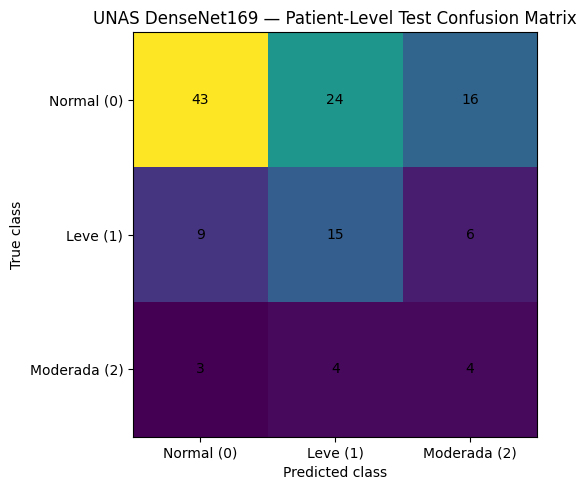

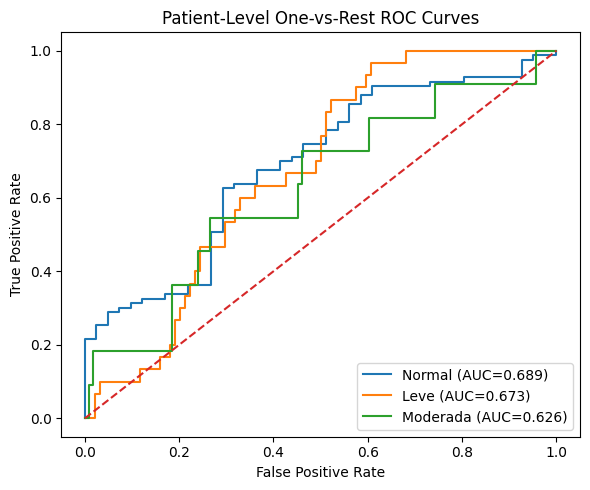

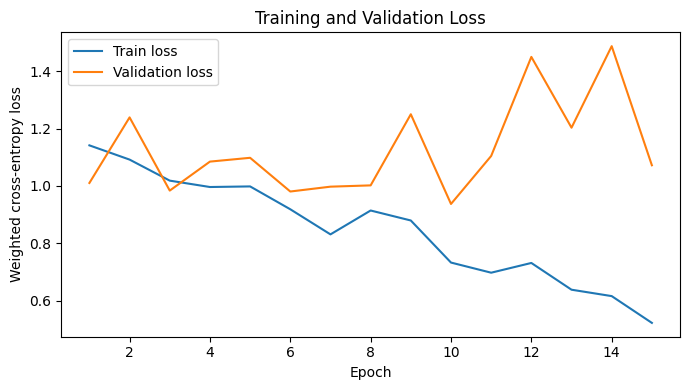

In [11]:
# Primary confusion matrix: patient-level, with the original three classes.
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, interpolation="nearest")
ax.set_title("UNAS DenseNet169 — Patient-Level Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks([0, 1, 2], ["Normal (0)", "Leve (1)", "Moderada (2)"])
ax.set_yticks([0, 1, 2], ["Normal (0)", "Leve (1)", "Moderada (2)"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.tight_layout()
cm_png = OUTPUT_DIR / "patient_level_test_confusion_matrix.png"
fig.savefig(cm_png, dpi=160, bbox_inches="tight")
plt.show()

# One-vs-rest ROC curves, one per class, when each class is represented in the test set.
from sklearn.preprocessing import label_binarize
patient_y_bin = label_binarize(patient_y, classes=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
roc_drawn = False
for class_idx, class_name in LABEL_NAMES.items():
    y_binary = (patient_y == class_idx).astype(int)
    if len(np.unique(y_binary)) < 2:
        print(f"Skipping ROC for {class_name}: test labels contain only one side of this one-vs-rest split.")
        continue
    fpr, tpr, _ = roc_curve(y_binary, patient_probabilities[:, class_idx])
    try:
        auc_value = roc_auc_score(y_binary, patient_probabilities[:, class_idx])
    except ValueError:
        auc_value = float("nan")
    ax.plot(fpr, tpr, label=f"{class_name} (AUC={auc_value:.3f})")
    roc_drawn = True
if roc_drawn:
    ax.plot([0, 1], [0, 1], linestyle="--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("Patient-Level One-vs-Rest ROC Curves")
    ax.legend(loc="lower right")
    fig.tight_layout()
    roc_png = OUTPUT_DIR / "patient_level_test_roc_curve.png"
    fig.savefig(roc_png, dpi=160, bbox_inches="tight")
    plt.show()
else:
    plt.close(fig)
    print("No ROC curve generated because the test split does not contain all needed class variation.")

hist_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_df["epoch"], hist_df["train_loss"], label="Train loss")
ax.plot(hist_df["epoch"], hist_df["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted cross-entropy loss")
ax.set_title("Training and Validation Loss")
ax.legend()
fig.tight_layout()
history_png = OUTPUT_DIR / "training_loss_curve.png"
fig.savefig(history_png, dpi=160, bbox_inches="tight")
plt.show()


## 8. Export predictions, split manifest, run metadata, and results ZIP

The output bundle includes the best checkpoint and latest checkpoint, metrics at patient and image level, confusion matrices, ROC/loss plots, per-image predictions, patient-aggregated predictions, split manifest, and training history.

In [12]:
image_predictions_df.to_csv(OUTPUT_DIR / "image_level_test_predictions.csv", index=False)
patient_predictions.to_csv(OUTPUT_DIR / "patient_level_test_predictions.csv", index=False)
df[["image_path", "patient_id", "original_class", "label", "split"]].to_csv(
    OUTPUT_DIR / "dataset_split_manifest.csv", index=False
)

run_info = {
    "paper": "Machine vision model using nail images for non-invasive detection of iron deficiency anemia in university students",
    "paper_doi": "10.3389/fdata.2025.1557600",
    "adaptation": "AnaeCare UNAS nail images only; DenseNet169 primary model; three-class classification",
    "label_mapping": {"0": "Normal", "1": "Leve", "2": "Moderada"},
    "class_to_label_original_folders": CLASS_TO_LABEL,
    "data_root": str(DATA_ROOT),
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "configured_epochs": EPOCHS,
    "completed_epochs": int(history[-1]["epoch"]) if history else 0,
    "best_epoch": int(checkpoint["epoch"]),
    "pretrained": USE_PRETRAINED,
    "device": str(DEVICE),
    "patient_counts_by_split": {s: len(x) for s, x in [("train", train_pat), ("val", val_pat), ("test", test_pat)]},
    "image_counts_by_split": df["split"].value_counts().to_dict(),
    "primary_patient_level_metrics": patient_metrics,
    "supplementary_image_level_metrics": image_metrics,
    "checkpoint_files": [CHECKPOINT_PATH.name, LATEST_CHECKPOINT_PATH.name],
    "note": "Paper-informed adaptation, not an exact reproduction; not a clinical diagnostic tool.",
}
with open(OUTPUT_DIR / "run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

zip_path = Path("/kaggle/working/AnaeCare_Nail_Methodology_Results.zip")
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file in sorted(OUTPUT_DIR.rglob("*")):
        if file.is_file() and file != zip_path:
            zf.write(file, arcname=str(Path("AnaeCare_Nail_Methodology_Results") / file.relative_to(OUTPUT_DIR)))
print("Results folder:", OUTPUT_DIR)
print("Results ZIP:", zip_path, "| bytes:", zip_path.stat().st_size)
print("Exported files:")
for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(" -", file.relative_to(OUTPUT_DIR), f"({file.stat().st_size:,} bytes)")


Results folder: /kaggle/working/anaecare_nail_densenet169
Results ZIP: /kaggle/working/AnaeCare_Nail_Methodology_Results.zip | bytes: 282079264
Exported files:
 - best_densenet169.pt (151,340,517 bytes)
 - dataset_split_manifest.csv (91,677 bytes)
 - image_level_test_confusion_matrix.csv (95 bytes)
 - image_level_test_metrics.csv (228 bytes)
 - image_level_test_predictions.csv (21,566 bytes)
 - latest_densenet169.pt (151,348,807 bytes)
 - patient_level_per_class_report.csv (388 bytes)
 - patient_level_test_confusion_matrix.csv (95 bytes)
 - patient_level_test_confusion_matrix.png (42,048 bytes)
 - patient_level_test_metrics.csv (205 bytes)
 - patient_level_test_predictions.csv (10,566 bytes)
 - patient_level_test_roc_curve.png (65,060 bytes)
 - run_info.json (1,746 bytes)
 - training_history.csv (1,906 bytes)
 - training_loss_curve.png (64,575 bytes)


## 9. Methodology notes and checks before reporting

1. **Single modality:** only UNAS nail images are used. Do not describe this as multimodal fusion.
2. **Three original classes:** `Normal=0`, `Leve=1`, `Moderada=2`; no class merging or binary anemia mapping is applied.
3. **Patient-level split:** images from one patient stay in one split. The manifest is exported so the split can be audited and reused.
4. **Primary evaluation:** patient-level mean-probability aggregation is used when multiple images exist per patient; image-level results are supplementary.
5. **Metrics:** accuracy, balanced accuracy, macro precision/recall/F1, and macro one-vs-rest ROC-AUC are reported. The confusion matrix is 3×3 and ordered Normal, Leve, Moderada.
6. **Checkpointing:** `best_densenet169.pt` stores the best validation-loss epoch; `latest_densenet169.pt` is updated after every completed epoch. Download the result ZIP before the Kaggle session ends.
7. **Preprocessing:** resize/center crop and training-only augmentation are pragmatic adaptations. This does not claim to reproduce the paper's exact segmentation procedure.
8. **Comparison:** the paper's reported accuracy/AUC come from a different dataset and experimental protocol, so they are contextual only, not directly comparable.
9. **Clinical scope:** this is research pre-screening only and must not be used for clinical diagnosis.
